Dataset shape: (10000, 14)

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Class balance (0 = Healthy, 1 = Failure):
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


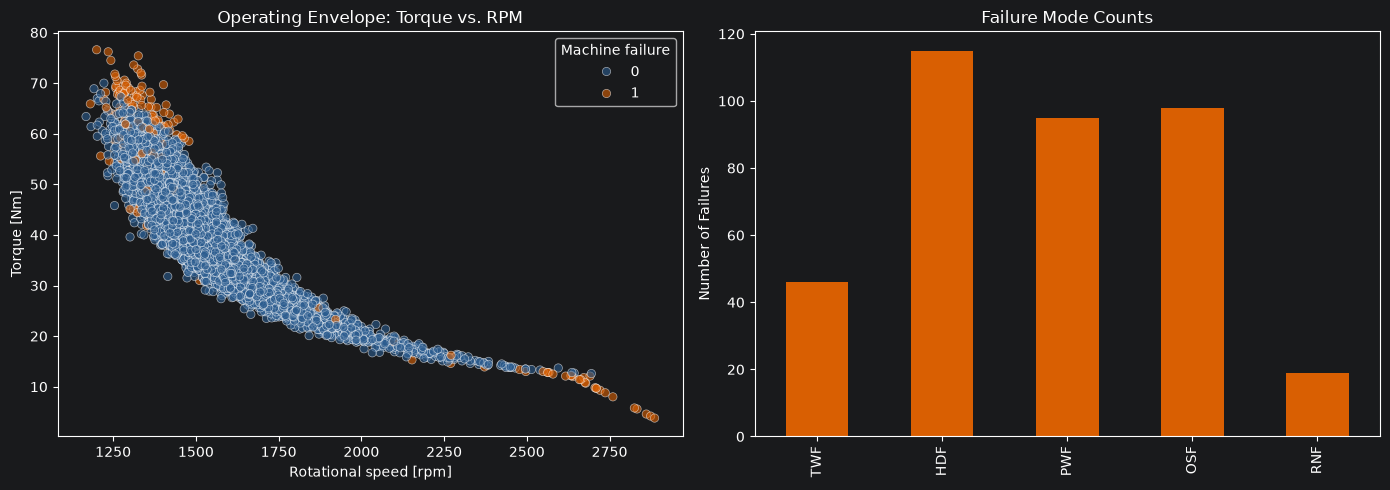

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv("../data/ai4i2020.csv")

print(f"Dataset shape: {df.shape}")
print("\nMissing values:\n", df.isnull().sum())
print("\nClass balance (0 = Healthy, 1 = Failure):")
print(df["Machine failure"].value_counts(normalize=True) * 100)

# 2. Physics-Informed Feature Engineering
# Mechanical Power (Watts) = Torque (Nm) * Angular Velocity (rad/s)
df["Angular_velocity_rad_s"] = df["Rotational speed [rpm]"] * (2 * np.pi / 60)
df["Power_W"] = df["Torque [Nm]"] * df["Angular_velocity_rad_s"]

# Thermal gradient between process and ambient air
df["Temp_diff_K"] = df["Process temperature [K]"] - df["Air temperature [K]"]

# 3. Visualize Failure Modes & Physical Boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Torque vs Rotational Speed colored by Machine Failure
sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    alpha=0.6,
    palette={0: "#2b5c8f", 1: "#d95f02"},
    ax=axes[0],
)
axes[0].set_title("Operating Envelope: Torque vs. RPM")

# Plot 2: Breakdown of specific failure types
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df[failure_cols].sum().plot(kind="bar", color="#d95f02", ax=axes[1])
axes[1].set_title("Failure Mode Counts")
axes[1].set_ylabel("Number of Failures")

plt.tight_layout()
plt.show()